# BIL545 · Proje 1
## 9.5 Online alışverişte satın alma niyeti

| | |
|---|---|
| Ders | Veri Madenciliğinde İleri Konular · 2026–2027 Güz |
| Öğrenci | Emircan Demir · 264309006 |
| Grup | Grup 7 |
| GitHub | [Proje deposu](https://github.com/EmircanDemirTR/bil545-online-alisveris) |

Grup dağıldıktan sonra hoca mailde sadece Bölüm 2'yi yapmam gerektiğini söyledi. Bölüm 1'i de ben ekledim.

**Araştırma sorusu.** Oturumda hangi sayfalara bakıldığı ve bu sayfalarda ne kadar kalındığı, satın almayla biten oturumları ayırmaya yardımcı oluyor mu? Elimde oturumun tamamına ait özetler var. Bu yüzden ziyaret sürerken ne kadar erken tahmin yapabileceğimi bu veriyle ölçemiyorum.

## Hazırlık

Colab'da defteri açtıktan sonra **Çalışma zamanı → Tümünü çalıştır** seçeneğini kullanın.

In [1]:
import hashlib
import io
import sys
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

SEED = 42
np.random.seed(SEED)
print("Python", sys.version.split()[0])
for library in (np, pd, sklearn, matplotlib):
    print(library.__name__, library.__version__)

Python 3.12.10
numpy 2.5.3
pandas 3.0.6
sklearn 1.9.1
matplotlib 3.11.2


### Veriyi yükleme

Defter CSV'yi çalışma klasöründe veya bir üst klasörde arıyor. Bulamazsa UCI'dan indiriyor. Hücre, kullanılan dosyanın SHA-256 özetini gösteriyor.

[UCI veri seti](https://doi.org/10.24432/C5F88Q) · [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

In [2]:
FILENAME = "online_shoppers_intention.csv"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
paths = (Path(FILENAME), Path("..") / FILENAME)
local_csv = next((path for path in paths if path.is_file()), None)

if local_csv is None:
    with urlopen(UCI_ZIP, timeout=45) as response:
        with ZipFile(io.BytesIO(response.read())) as archive:
            csv_bytes = archive.read(FILENAME)
else:
    csv_bytes = local_csv.read_bytes()

print("Girdi:", "UCI arşivi" if local_csv is None else local_csv)
print("SHA-256:", hashlib.sha256(csv_bytes).hexdigest())

Girdi: UCI arşivi
SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9


# Bölüm 1 · Veri, ön işleme ve sızıntı

Kaufman vd.'nin makalesinde sızıntıyı anlamak için tahmin anında eldeki bilgiye bakılıyor. Bu projede de önce sütunların ne zaman hesaplandığına baktım. Ana modelde ölçekleme ve kodlama ayarlarını her seferinde eğitim katından aldım. [Kaufman vd. (2012)](https://doi.org/10.1145/2382577.2382579)

### 1.1 Veri künyesi

| Soru | Cevap |
|---|---|
| Veri nereden geliyor? | Sakar vd. bu veriyi bir e-ticaret sitesindeki satın alma ve siteyi terk etme davranışını incelemek için kullandı. Sakar ve Kastro tabloyu UCI'da yayımladı. |
| Hangi dönem? | UCI bir yıl içindeki farklı kullanıcılardan alınan oturumları bildiriyor. CSV'de yalnızca ay adı var. 2018, UCI'da yayımlandığı yıl. |
| Hedef ne? | *Revenue*, oturumda bir satın alma olup olmadığını gösteriyor. Niyeti doğrudan ölçmüyor. Alışveriş yapmayı düşünüp siteden çıkan biri de negatif sınıfa giriyor. |
| Kimler az temsil ediliyor olabilir? | Veri tek mağazadan. Bazı aylar ve trafik türleri az görülüyor. Yaş ve gelir bilgisi olmadığı için bu grupları karşılaştıramıyorum. |
| Lisans | CC BY 4.0 |

In [3]:
df_raw = pd.read_csv(io.BytesIO(csv_bytes), na_values=["?"])
calendar = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = (
    df_raw.groupby("Month")["Revenue"].agg(["size", "sum", "mean"])
    .reindex(calendar)
    .rename(columns={"size": "Oturum", "sum": "Satın alma", "mean": "Satın alma oranı"})
)
display(by_month.style.format(
    {"Oturum": "{:.0f}", "Satın alma": "{:.0f}", "Satın alma oranı": "{:.2%}"},
    na_rep="—",
))

,Oturum,Satın alma,Satın alma oranı
Month,,,
Jan,—,—,—
Feb,184,3,1.63%
Mar,1907,192,10.07%
Apr,—,—,—
May,3364,365,10.85%
June,288,29,10.07%
Jul,432,66,15.28%
Aug,433,76,17.55%
Sep,448,86,19.20%


**Yorum.** Ocak ve nisanda kayıt yok. Oturumların yaklaşık yarısı mayıs ve kasımdan geliyor. Elimde tam tarih ve kampanya bilgisi olmadığı için farkın mevsimden kaynaklanıp kaynaklanmadığını söyleyemiyorum.

### 1.2 Keşifsel analiz

Tabloda sütunun dosyada nasıl saklandığıyla neyi ifade ettiğini ayrı gösterdim. Örneğin tarayıcı kodu sayı olarak saklanıyor ama bir kategori.

Negatif sayısal değer sayısı: 0
Ham tablo: 12.330 satır × 18 sütun


,Saklama,Ölçek,Eksik (%),Farklı değer,En küçük,Sıfır (%)
Sütun,,,,,,
Administrative,int64,Oran · sayım,"0,00",27,0,"46,78"
Administrative_Duration,float64,Oran · süre,"0,00",3335,0,"47,88"
Informational,int64,Oran · sayım,"0,00",17,0,"78,66"
Informational_Duration,float64,Oran · süre,"0,00",1258,0,"80,49"
ProductRelated,int64,Oran · sayım,"0,00",311,0,"0,31"
ProductRelated_Duration,float64,Oran · süre,"0,00",9551,0,"6,12"
BounceRates,float64,Oran · pay,"0,00",1872,0,"44,75"
ExitRates,float64,Oran · pay,"0,00",4777,0,"0,62"
PageValues,float64,Oran · metrik değer,"0,00",2704,0,"77,86"


Tam tekrar, ilk satır hariç: 125
Seçili özniteliklerde ek tekrar: 6
Seçili öznitelikleri aynı, etiketleri farklı gruplar: 0


,Ham,Deney,Ham (%),Deney (%)
Satın alma yok,10.422,10.291,"84,53","84,36"
Satın alma var,1.908,1.908,"15,47","15,64"


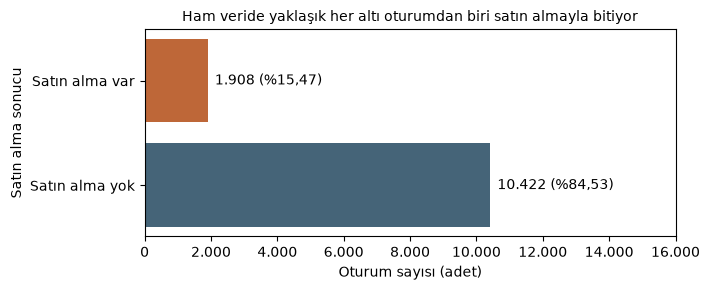

In [4]:
page_counts = ["Administrative", "Informational", "ProductRelated"]
durations = [f"{column}_Duration" for column in page_counts]
analytics = ["BounceRates", "ExitRates", "PageValues"]
nominal = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
target = "Revenue"
categorical = nominal + ["Weekend"]
numeric = page_counts + durations + ["SpecialDay"]
features = numeric + categorical
scale = {
    **dict.fromkeys(page_counts, "Oran · sayım"),
    **dict.fromkeys(durations, "Oran · süre"),
    "BounceRates": "Oran · pay",
    "ExitRates": "Oran · pay",
    "PageValues": "Oran · metrik değer",
    "SpecialDay": "Sıralı · yakınlık puanı",
    **dict.fromkeys(nominal, "Nominal kategori"),
    "Weekend": "İkili kategori",
    "Revenue": "İkili hedef",
}
assert set(df_raw.columns) == set(scale)
assert df_raw[target].isin([True, False]).all()
negative_count = int(df_raw.select_dtypes(include="number").lt(0).sum().sum())
print("Negatif sayısal değer sayısı:", negative_count)

def audit_table(frame):
    rows = []
    for name, values in frame.items():
        rows.append({
            "Sütun": name,
            "Saklama": str(values.dtype),
            "Ölçek": scale[name],
            "Eksik (%)": 100 * values.isna().mean(),
            "Farklı değer": values.nunique(),
            "En küçük": values.min() if name in numeric + analytics else np.nan,
            "Sıfır (%)": 100 * values.eq(0).mean() if name in numeric + analytics else np.nan,
        })
    return pd.DataFrame(rows).set_index("Sütun")

row_count = f"{len(df_raw):,}".replace(",", ".")
print(f"Ham tablo: {row_count} satır × {df_raw.shape[1]} sütun")
display(audit_table(df_raw).style.format(
    {"Eksik (%)": "{:.2f}", "Sıfır (%)": "{:.2f}", "En küçük": "{:g}"},
    na_rep="—", decimal=","
))

raw_duplicates = df_raw.duplicated()
df_unique = df_raw.loc[~raw_duplicates].copy()
feature_duplicates = df_unique.duplicated(subset=features)
same_features = df_unique.loc[df_unique.duplicated(subset=features, keep=False)]
conflicting_targets = (
    same_features.groupby(features, dropna=False)[target].nunique().gt(1).sum()
)
print(f"Tam tekrar, ilk satır hariç: {raw_duplicates.sum()}")
print(f"Seçili özniteliklerde ek tekrar: {feature_duplicates.sum()}")
print(f"Seçili öznitelikleri aynı, etiketleri farklı gruplar: {conflicting_targets}")
assert conflicting_targets == 0, "Öznitelikleri aynı ama etiketleri farklı oturumlar incelenmeli."
df_clean = df_unique.loc[~feature_duplicates].reset_index(drop=True)
X = df_clean[features].copy()
y = df_clean[target].astype(int)

class_counts = pd.DataFrame({
    "Ham": df_raw[target].value_counts(),
    "Deney": df_clean[target].value_counts(),
}).reindex([False, True])
class_counts.index = ["Satın alma yok", "Satın alma var"]
for name in ["Ham", "Deney"]:
    class_counts[f"{name} (%)"] = 100 * class_counts[name] / class_counts[name].sum()
display(class_counts.style.format(
    {"Ham (%)": "{:.2f}", "Deney (%)": "{:.2f}"}, thousands=".", decimal=","
))

fig, ax = plt.subplots(figsize=(7.2, 3))
bars = ax.barh(class_counts.index, class_counts["Ham"], color=["#456478", "#be6738"])
counts = [f"{count:,}".replace(",", ".") for count in class_counts["Ham"]]
percentages = [f"%{pct:.2f}".replace(".", ",") for pct in class_counts["Ham (%)"]]
ax.bar_label(bars, labels=[f"{count} ({pct})" for count, pct in zip(counts, percentages)],
             padding=5)
ax.set(xlabel="Oturum sayısı (adet)", ylabel="Satın alma sonucu", xlim=(0, 16000))
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}".replace(",", "."))
ax.set_title("Ham veride yaklaşık her altı oturumdan biri satın almayla bitiyor", fontsize=10)
plt.tight_layout()
plt.show()

**Yorum.** 12.330 oturumun %15,47'si satın almayla bitmiş. Birebir aynı 125 satır ve ana modelin kullandığı sütunlarda aynı olan 6 satır daha vardı. Bunları farklı katlara dağıtmamak için her gruptan bir satır bıraktım. Çıkardığım 131 satırın tamamı satın almasızdı. Oturum kimliği olmadığı için bazıları gerçekten farklı ziyaretlere ait olabilir. Son tabloda 12.199 oturum kaldı. Satın alma oranı %15,64 oldu.

| Sütun | Kararım |
|---|---|
| Kategorik kodlar | *OperatingSystems*, *Browser*, *Region* ve *TrafficType* değerlerini kategori olarak kullandım. |
| Sıfırlar ve *VisitorType=Other* | Belgelenmiş bir eksik kodu olmadığı için olduğu gibi bıraktım. Sayısal sütunlarda −1 gibi bir negatif değer de çıkmadı. |
| *PageValues* | Satın almayla bağlantılı bir metrik. Hesabın hangi döneme ait olduğunu dosyadan göremediğim için ana modele almadım. |
| *BounceRates* ve *ExitRates* | Bu oranların ne zaman hesaplandığı belli olmadığı için ana modele almadım. |
| Sayfa sayısı ve süre | Bunları oturum sonunda bilinen değerler olarak kullandım. |

### 1.3 Eksiklik analizi

CSV'de boş hücre, soru işareti ve benzeri eksik kodları aradım. Sonra iki süre sütununa kontrollü olarak eksik değer ekledim.

Aday eksik işareti sayısı: 0
NaN'a dönüşen veya doğal olarak eksik hücre: 0


,Oturum sayısı
Oturum başına eksik hücre,
0,12330


,Sayfa yok ve süre 0,Sayfa var ve süre 0
Süre,,
Administrative_Duration,5768,135
Informational_Duration,9699,226
ProductRelated_Duration,38,717


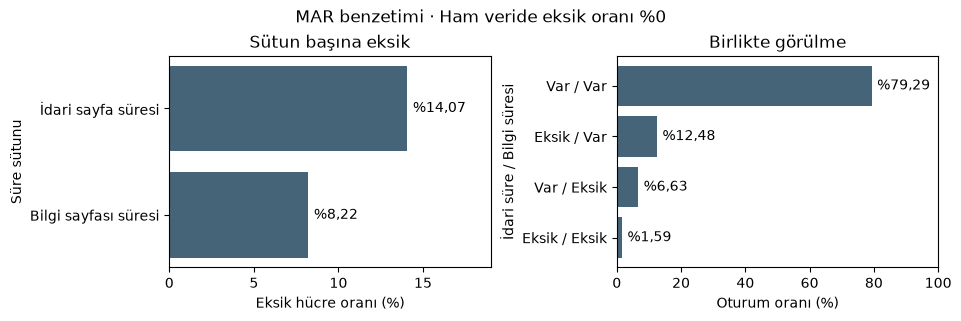

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Medyan,0.2998 ± 0.0184,0.7133 ± 0.0103,0.5127 ± 0.0040,0.0611 ± 0.0137,0.0328 ± 0.0076
Medyan + gösterge,0.3002 ± 0.0192,0.7152 ± 0.0102,0.5127 ± 0.0042,0.0619 ± 0.0147,0.0333 ± 0.0082


Göstergenin eşleştirilmiş AP farkı: +0.0004 ± 0.0035


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

raw_tokens = pd.read_csv(io.BytesIO(csv_bytes), dtype=str, keep_default_na=False)
missing_tokens = {"", "?", "na", "n/a", "nan", "null"}
token_mask = raw_tokens.apply(lambda column: column.str.strip().str.lower().isin(missing_tokens))
print("Aday eksik işareti sayısı:", token_mask.sum().sum())
print("NaN'a dönüşen veya doğal olarak eksik hücre:", df_raw.isna().sum().sum())
patterns = df_raw.isna().sum(axis=1).value_counts().sort_index()
display(patterns.rename_axis("Oturum başına eksik hücre").to_frame("Oturum sayısı"))
assert not token_mask.any().any() and not df_raw.isna().any().any(), "Eksik desenini yeniden inceleyin."

zero_audit = pd.DataFrame([
    {
        "Süre": duration,
        "Sayfa yok ve süre 0": (df_raw[count].eq(0) & df_raw[duration].eq(0)).sum(),
        "Sayfa var ve süre 0": (df_raw[count].gt(0) & df_raw[duration].eq(0)).sum(),
    }
    for count, duration in zip(page_counts, durations)
]).set_index("Süre")
display(zero_audit)

# Ölçüm kaybı, ilgili kategoride sayfa gören oturumlarda uygulanır.
# Olasılık gözlenen sayaçtan gelir ve etiketi kullanmaz.
rng = np.random.default_rng(SEED)
X_missing = X.copy()
simulated = ["Administrative_Duration", "Informational_Duration"]
for duration in simulated:
    visited = X[duration.removesuffix("_Duration")]
    probability = np.select([visited.eq(0), visited.le(2)], [0.0, 0.50], default=0.12)
    X_missing[duration] = X[duration].mask(rng.random(len(X)) < probability)

status = X_missing[simulated].isna().replace({False: "Var", True: "Eksik"})
order = [("Var", "Var"), ("Eksik", "Var"), ("Var", "Eksik"), ("Eksik", "Eksik")]
pattern = status.value_counts(normalize=True).reindex(order, fill_value=0).mul(100)
rates = X_missing[simulated].isna().mean().mul(100)

fig, (rates_ax, pattern_ax) = plt.subplots(1, 2, figsize=(9.5, 3.1), layout="constrained")
for ax, labels, values, limit in [
    (rates_ax, ["İdari sayfa süresi", "Bilgi sayfası süresi"], rates, 19),
    (pattern_ax, [" / ".join(pair) for pair in order], pattern, 100),
]:
    bars = ax.barh(labels, values, color="#456478")
    ax.bar_label(bars, [f"%{value:.2f}".replace(".", ",") for value in values], padding=4)
    ax.set_xlim(0, limit)
    ax.invert_yaxis()
rates_ax.set(title="Sütun başına eksik", xlabel="Eksik hücre oranı (%)", ylabel="Süre sütunu")
pattern_ax.set(title="Birlikte görülme", xlabel="Oturum oranı (%)",
               ylabel="İdari süre / Bilgi süresi")
fig.suptitle("MAR benzetimi · Ham veride eksik oranı %0")
plt.show()

outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
splits = list(outer_cv.split(X, y))
SCORING = {
    "AP": "average_precision",
    "ROC AUC": "roc_auc",
    "Dengeli doğruluk": "balanced_accuracy",
    "F1": "f1",
    "Duyarlılık": "recall",
}

def preprocessing(traffic_encoder=None, indicator=False, extra_numeric=()):
    num = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=indicator)),
        ("scale", StandardScaler()),
    ])
    if traffic_encoder is None:
        traffic_encoder = OneHotEncoder(handle_unknown="ignore")
    other_categories = [c for c in categorical if c != "TrafficType"]
    return ColumnTransformer([
        ("sayisal", num, numeric + list(extra_numeric)),
        ("kategori", OneHotEncoder(handle_unknown="ignore"), other_categories),
        ("trafik", traffic_encoder, ["TrafficType"]),
    ])

def logistic(preprocessor):
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=1000)),
    ])

def fold_scores(estimator, data, cv=splits):
    evaluated = cross_validate(estimator, data, y, cv=cv, scoring=SCORING, error_score="raise")
    return pd.DataFrame({name: evaluated[f"test_{name}"] for name in SCORING})

def score_summary(results):
    return pd.DataFrame({
        name: table.apply(lambda column: f"{column.mean():.4f} ± {column.std():.4f}")
        for name, table in results.items()
    }).T

def paired_ap(first, second):
    delta = second["AP"] - first["AP"]
    return f"{delta.mean():+.4f} ± {delta.std():.4f}"

missing_scores = {
    "Medyan": fold_scores(logistic(preprocessing()), X_missing),
    "Medyan + gösterge": fold_scores(logistic(preprocessing(indicator=True)), X_missing),
}
display(score_summary(missing_scores))
print("Göstergenin eşleştirilmiş AP farkı:", paired_ap(*missing_scores.values()))

**Yorum.** Ham veride eksik hücre çıkmadı. Bir sayfa türü hiç ziyaret edilmediyse sürenin 0 olması beklenir. Sayfa ziyaret edildiği hâlde sürenin neden 0 olduğunu ise bu tablodan anlayamıyorum.

Benzetimde idari sayfa ve bilgi sayfası sürelerini, bilinen sayfa sayısına göre gizledim. Satın alma etiketini kullanmadım. Bu yüzden benzetimdeki eksiklik MAR. Gerçek veri için bir mekanizma çıkaramıyorum. Grafiğin sağı iki sürenin aynı oturumda nasıl eksik kaldığını gösteriyor. İki süre birden oturumların %1,59'unda eksik kaldı. Eksik göstergesini ekleyince AP farkı +0,0004 ± 0,0035 oldu. Etki küçük. Model, maskelemede kullanılan sayfa sayısını zaten görüyor.

### 1.4 Kategorik kodlama

20 farklı değeri olan *TrafficType* sütununu seçtim. Bazı değerler yalnızca bir kere geçiyor. Karşılaştırmada sadece bu sütunun kodlamasını değiştirdim.

In [6]:
traffic_counts = X["TrafficType"].value_counts().sort_index()
display(traffic_counts.rename_axis("Trafik kodu").to_frame("Oturum sayısı").T)
print("20'den az gözlemli kategori sayısı:", traffic_counts.lt(20).sum())

def traffic_target_encoder():
    options = {"target_type": "binary", "smooth": 10}
    sklearn_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
    if sklearn_version >= (1, 9):
        inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
        return TargetEncoder(cv=inner_cv, **options)
    return TargetEncoder(cv=5, random_state=SEED, **options)

onehot = logistic(preprocessing())
rare = logistic(preprocessing(
    traffic_encoder=OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist")
))
target_encoded = logistic(preprocessing(traffic_encoder=traffic_target_encoder()))

# Bilerek yanlış: doğrulama etiketleri kategori ortalamalarına giriyor.
traffic = X[["TrafficType"]]
global_traffic = traffic_target_encoder().fit(traffic, y).transform(traffic)
X_wrong_encoding = X.assign(TrafficType=global_traffic.ravel())
fixed_numeric_traffic = logistic(preprocessing(traffic_encoder="passthrough"))

encoding_scores = {
    "One-hot": fold_scores(onehot, X),
    "Nadirleri birleştiren one-hot": fold_scores(rare, X),
    "Kat dışı hedef kodlama": fold_scores(target_encoded, X),
    "Tüm etiketlerle hedef kodlama (yanlış)": fold_scores(fixed_numeric_traffic, X_wrong_encoding),
}
display(score_summary(encoding_scores))
print("Yanlış − kat dışı kodlama, eşleştirilmiş AP farkı:",
      paired_ap(encoding_scores["Kat dışı hedef kodlama"],
                encoding_scores["Tüm etiketlerle hedef kodlama (yanlış)"]))

Trafik kodu,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Oturum sayısı,2384,3910,2013,1066,260,443,40,343,41,450,247,1,728,13,37,3,1,10,17,192


20'den az gözlemli kategori sayısı: 6


,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
One-hot,0.2998 ± 0.0183,0.7132 ± 0.0103,0.5128 ± 0.0038,0.0616 ± 0.0134,0.0331 ± 0.0074
Nadirleri birleştiren one-hot,0.2999 ± 0.0185,0.7132 ± 0.0105,0.5128 ± 0.0039,0.0614 ± 0.0137,0.0330 ± 0.0076
Kat dışı hedef kodlama,0.3002 ± 0.0179,0.7132 ± 0.0106,0.5108 ± 0.0040,0.0538 ± 0.0134,0.0287 ± 0.0073
Tüm etiketlerle hedef kodlama (yanlış),0.3020 ± 0.0182,0.7153 ± 0.0107,0.5114 ± 0.0040,0.0562 ± 0.0136,0.0301 ± 0.0075


Yanlış − kat dışı kodlama, eşleştirilmiş AP farkı: +0.0018 ± 0.0010


**Yorum.** Eğitim katında 20'den az görülen trafik türlerini birleştirdim. Doğru hedef kodlamada, bir eğitim satırının kodunu hesaplarken kendi etiketini kullanmadım. Doğrulama satırlarını da yalnızca eğitim verisinden öğrenilen kodlarla çevirdim.

Yanlış kurulumda doğrulama etiketleri de ortalamaya girdi. AP 0,3002 yerine 0,3020 çıktı. *smooth=10* az görülen kategorilerin kodunu genel satın alma oranına yaklaştırıyor. Farkın küçük kalmasında bunun payı olabilir. Üç geçerli yöntem birbirine yakın çıktığı için ana modelde one-hot kullandım.

### 1.5 Sızıntı deneyi

İlk deneyde ön işlemenin tüm veride yapılmasıyla eğitim katında yapılmasını karşılaştırdım. Sonra ana modele ayrı ayrı *PageValues* ve iki çıkış oranını ekledim. Katları değiştirmedim.

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Kat içinde ön işleme,0.2998 ± 0.0183,0.7132 ± 0.0103,0.5128 ± 0.0038,0.0616 ± 0.0134,0.0331 ± 0.0074
Tüm veride ön işleme (yanlış),0.2998 ± 0.0185,0.7132 ± 0.0104,0.5128 ± 0.0039,0.0614 ± 0.0137,0.0330 ± 0.0076
PageValues,0.6374 ± 0.0212,0.8939 ± 0.0078,0.6772 ± 0.0113,0.5002 ± 0.0223,0.3803 ± 0.0235
BounceRates + ExitRates,0.3274 ± 0.0202,0.7466 ± 0.0111,0.5113 ± 0.0052,0.0546 ± 0.0188,0.0291 ± 0.0103


Tüm veride ön işleme (yanlış) — ana modele göre AP farkı: +0.0000 ± 0.0003
PageValues — ana modele göre AP farkı: +0.3376 ± 0.0203
BounceRates + ExitRates — ana modele göre AP farkı: +0.0276 ± 0.0133


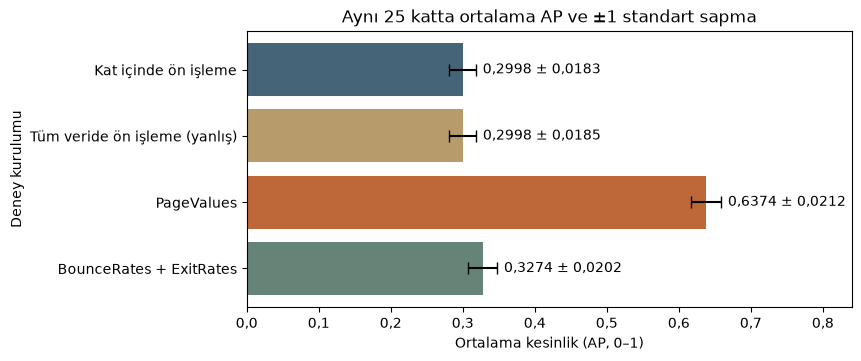

,Oturum,Satın alma,Satın alma oranı
PageValues,,,
PageValues = 0,9469,370,3.91%
PageValues > 0,2730,1538,56.34%


In [7]:
# Bilerek yanlış: StandardScaler ve kodlayıcı test katının X değerlerini görüyor.
all_preprocessed = preprocessing().fit_transform(X)
global_score = fold_scores(LogisticRegression(max_iter=1000), all_preprocessed)

correct_score = encoding_scores["One-hot"]
leakage_scores = {
    "Kat içinde ön işleme": correct_score,
    "Tüm veride ön işleme (yanlış)": global_score,
}
for columns in (["PageValues"], ["BounceRates", "ExitRates"]):
    model = logistic(preprocessing(extra_numeric=columns))
    leakage_scores[" + ".join(columns)] = fold_scores(model, df_clean[features + columns])

display(score_summary(leakage_scores))
for name, scores in list(leakage_scores.items())[1:]:
    print(f"{name} — ana modele göre AP farkı:", paired_ap(correct_score, scores))

means = [scores["AP"].mean() for scores in leakage_scores.values()]
stds = [scores["AP"].std() for scores in leakage_scores.values()]
fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
bars = ax.barh(list(leakage_scores), means, xerr=stds, capsize=4,
               color=["#456478", "#b79b6b", "#be6738", "#668377"])
ap_labels = [f"{mean:.4f} ± {std:.4f}".replace(".", ",") for mean, std in zip(means, stds)]
ax.bar_label(bars, labels=ap_labels, padding=5)
ax.invert_yaxis()
ax.set(xlabel="Ortalama kesinlik (AP, 0–1)", ylabel="Deney kurulumu", xlim=(0, 0.84),
       title="Aynı 25 katta ortalama AP ve ±1 standart sapma")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.1f}".replace(".", ","))
plt.show()

page_groups = (
    df_clean.groupby(df_clean["PageValues"].gt(0))[target].agg(["size", "sum", "mean"])
    .rename(index={False: "PageValues = 0", True: "PageValues > 0"},
            columns={"size": "Oturum", "sum": "Satın alma", "mean": "Satın alma oranı"})
)
display(page_groups.style.format({"Satın alma oranı": "{:.2%}"}))

**Yorum.** Ön işleme tüm tabloda yapılınca doğrulama satırları ölçek ve kategori hesaplarına giriyor. Burada iki AP de dört basamakla 0,2998 çıktı. Örneğin hiç eksik olmadığı için medyan doldurma zaten sonucu değiştirmedi.

*PageValues* eklenince AP 0,6374'e çıktı. Değer pozitifken oturumların yaklaşık %56'sı, sıfırken %4'ü satın almayla bitmiş. Bu tek başına sızıntıyı kanıtlamıyor. *BounceRates* ve *ExitRates* birlikte eklenince AP 0,3274 ± 0,0202 oldu. Modelin tahmin anında bu üç metriğe erişebileceğini doğrulayamadığım için onları ana modelden çıkardım. Grafikteki hata çubukları katlar arasındaki standart sapmayı gösteriyor.

### 1.6 Baseline ve ilk model

Dummy modeli her oturuma çoğunluk etiketini veriyor. Lojistik regresyonla aynı 5 kat ve 5 tekrarda karşılaştırdım. Satın alma az görüldüğü için ana ölçütüm AP (ortalama kesinlik).

In [8]:
dummy = Pipeline([
    ("preprocess", preprocessing()),
    ("model", DummyClassifier(strategy="most_frequent")),
])
main_scores = {
    "Dummy · çoğunluk": fold_scores(dummy, X),
    "Lojistik regresyon": correct_score,
}
display(score_summary(main_scores))
print("Lojistik − Dummy, eşleştirilmiş AP farkı:", paired_ap(*main_scores.values()))

# Dış katlar model deneylerinin tamamında aynı satır indekslerini kullanır.
for train, test in splits:
    assert not np.intersect1d(train, test).size
    assert len(train) + len(test) == len(X)
    assert y.iloc[test].nunique() == 2
assert len(splits) == 25 and not X.duplicated().any()

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Dummy · çoğunluk,0.1564 ± 0.0002,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Lojistik regresyon,0.2998 ± 0.0183,0.7132 ± 0.0103,0.5128 ± 0.0038,0.0616 ± 0.0134,0.0331 ± 0.0074


Lojistik − Dummy, eşleştirilmiş AP farkı: +0.1434 ± 0.0183


**Yorum.** Dummy hiç satın alma tahmini yapmadı. Lojistik regresyonun AP'si 0,2998, ROC AUC'si 0,7132 çıktı. Sıralama iyileşti ama varsayılan 0,5 eşiğinde satın almaların ortalama %3,3'ünü yakaladı. Bu bölümde eşik ayarı yapmadım.

### 1.7 Weka ile bağımsız kontrol

Aynı 12.199 oturumu ve 14 özniteliği ARFF'ye aktardım. Kategori kodlarını nominal bıraktım. Weka 3.8.6'da ZeroR ve J48'i 10 katla çalıştırdım. Defter JAR dosyalarını indiriyor. Yerelde Weka hücresi için Java gerekiyor.

In [9]:
import os
import shutil
import subprocess
from tempfile import TemporaryDirectory

from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, f1_score, recall_score, roc_auc_score,
)

java = shutil.which("java")
if java is None and "google.colab" in sys.modules:
    subprocess.run(["apt-get", "-qq", "update"], check=True, timeout=180)
    subprocess.run(["apt-get", "-qq", "install", "-y", "openjdk-17-jre-headless"],
                   check=True, timeout=240)
    java = shutil.which("java")
if java is None:
    raise RuntimeError("Weka için Java kurup java komutunu PATH'e ekleyin veya Colab kullanın.")

weka_data = X.assign(Revenue=y.astype(bool))
arff_lines = ["@relation online_shoppers"]
for column in weka_data:
    if column in categorical + [target]:
        levels = ",".join(map(str, sorted(weka_data[column].unique())))
        arff_lines.append(f"@attribute {column} {{{levels}}}")
    else:
        arff_lines.append(f"@attribute {column} numeric")

arff_text = ("\n".join(arff_lines + ["@data"]) + "\n" +
             weka_data.to_csv(header=False, index=False, lineterminator="\n"))

maven = "https://repo.maven.apache.org/maven2/nz/ac/waikato/cms/weka"
jars = {
    "weka-stable/3.8.6/weka-stable-3.8.6.jar":
        "932ea2f342b58fe45736389e9c426d5b5955e610d1f5f6485117f532068915e9",
    "thirdparty/bounce/0.18/bounce-0.18.jar":
        "bffff1505335c02256b7ab2ccffbe4aa4d3ac9fe14c17557809b7c9d99d666ca",
}

weka_commands = {"Weka ZeroR": "rules.ZeroR", "Weka J48": "trees.J48"}
weka_scores = {}
with TemporaryDirectory(prefix="bil545-") as directory:
    work = Path(directory)
    classpath = []
    for jar, expected_sha in jars.items():
        with urlopen(f"{maven}/{jar}", timeout=45) as response:
            content = response.read()
        if hashlib.sha256(content).hexdigest() != expected_sha:
            raise ValueError(f"Weka bağımlılığının SHA-256 değeri eşleşmedi: {jar}")
        jar_file = work / Path(jar).name
        jar_file.write_bytes(content)
        classpath.append(str(jar_file))

    arff = work / "online_shoppers.arff"
    arff.write_text(arff_text, encoding="ascii")

    for name, classifier in weka_commands.items():
        predictions = work / "predictions.csv"
        csv_options = (
            'weka.classifiers.evaluation.output.prediction.CSV '
            f'-file "{predictions.as_posix()}" -suppress -distribution -decimals 12'
        )
        command = [
            java, "-Djava.awt.headless=true", "-Dfile.encoding=UTF-8",
            "-Duser.language=en", "-Duser.country=US", "-cp", os.pathsep.join(classpath),
            f"weka.classifiers.{classifier}", "-t", str(arff), "-c", "last",
            "-x", "10", "-s", str(SEED), "-v", "-o",
        ]
        # Weka CLI, özet ve satır tahminlerini iki farklı çıktı kipinde verir.
        java_options = {"cwd": work, "capture_output": True, "text": True,
                        "encoding": "utf-8", "errors": "replace", "timeout": 90}
        summary = subprocess.run(command, **java_options)
        run = subprocess.run(command + ["-classifications", csv_options], **java_options)
        if summary.returncode or "Stratified cross-validation" not in summary.stdout:
            raise RuntimeError(f"{name} (özet)\n{summary.stdout}\n{summary.stderr}")
        if run.returncode or not predictions.is_file():
            raise RuntimeError(f"{name} (tahminler)\n{run.stdout}\n{run.stderr}")
        report = summary.stdout[summary.stdout.index("==="):].strip()
        print(f"\n{name} · Weka 3.8.6\n{report}")

        pred = pd.read_csv(
            predictions, header=None, skiprows=1, usecols=[0, 1, 2, 5],
        )
        pred.columns = ["instance", "actual", "predicted", "positive_probability"]
        pred["fold"] = pred["instance"].eq(1).cumsum()
        assert pred["fold"].nunique() == 10 and len(pred) == len(y)
        actual_all = pred["actual"].str.endswith(":True")
        assert actual_all.sum() == y.sum()
        metrics = []
        for _, group in pred.groupby("fold", sort=True):
            actual = group["actual"].str.endswith(":True")
            predicted = group["predicted"].str.endswith(":True")
            probability = group["positive_probability"].astype(str).str.lstrip("*").astype(float)
            metrics.append({
                "AP": average_precision_score(actual, probability),
                "ROC AUC": roc_auc_score(actual, probability),
                "Dengeli doğruluk": balanced_accuracy_score(actual, predicted),
                "F1": f1_score(actual, predicted, zero_division=0),
                "Duyarlılık": recall_score(actual, predicted),
            })
        weka_scores[name] = pd.DataFrame(metrics)
        predictions.unlink()

python_10fold = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
comparison = {
    "Python Dummy": fold_scores(dummy, X, cv=python_10fold),
    "Python lojistik": fold_scores(onehot, X, cv=python_10fold),
    **weka_scores,
}
display(score_summary(comparison))


Weka ZeroR · Weka 3.8.6
=== Stratified cross-validation ===

Correctly Classified Instances       10291               84.3594 %
Incorrectly Classified Instances      1908               15.6406 %
Kappa statistic                          0     
Mean absolute error                      0.2639
Root mean squared error                  0.3632
Relative absolute error                100      %
Root relative squared error            100      %
Total Number of Instances            12199     


=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 1.000    1.000    0.844      1.000    0.915      ?        0.500     0.843     False
                 0.000    0.000    ?          0.000    ?          ?        0.500     0.156     True
Weighted Avg.    0.844    0.844    ?          0.844    ?          ?        0.500     0.736     


=== Confusion Matrix ===

     a     b   <-- classified as
 10291     0 | 


Weka J48 · Weka 3.8.6
=== Stratified cross-validation ===

Correctly Classified Instances       10264               84.138  %
Incorrectly Classified Instances      1935               15.862  %
Kappa statistic                          0.0927
Mean absolute error                      0.2453
Root mean squared error                  0.3594
Relative absolute error                 92.947  %
Root relative squared error             98.9377 %
Total Number of Instances            12199     


=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 0.983    0.921    0.852      0.983    0.913      0.138    0.646     0.892     False
                 0.079    0.017    0.459      0.079    0.134      0.138    0.646     0.264     True
Weighted Avg.    0.841    0.780    0.790      0.841    0.791      0.138    0.646     0.793     


=== Confusion Matrix ===

     a     b   <-- classified as
 10114   177 |   

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Python Dummy,0.1564 ± 0.0003,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Python lojistik,0.3030 ± 0.0275,0.7128 ± 0.0156,0.5134 ± 0.0061,0.0633 ± 0.0216,0.0341 ± 0.0119
Weka ZeroR,0.1564 ± 0.0003,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Weka J48,0.2430 ± 0.0283,0.6311 ± 0.0490,0.5307 ± 0.0122,0.1335 ± 0.0388,0.0786 ± 0.0243


**Yorum.** ZeroR da Python'daki Dummy gibi hiç satın alma tahmini yapmadı. J48 ise 1.908 satın almanın 150'sini buldu. Buna rağmen doğruluğu ZeroR'dan biraz düşük çıktı. Veri dengesizken sadece doğruluğa baksaydım ZeroR daha iyi görünürdü.

Karşılaştırma tablosunda Weka'nın tahminlerinden AP'yi Python'la aynı şekilde hesapladım. J48'in AP'si 0,2430 ± 0,0283, ZeroR'ınki 0,1564 ± 0,0003 oldu. J48 ve lojistik regresyon farklı modeller. Weka ile Python oturumları da aynı katlara dağıtmıyor. Bu yüzden skorları yaklaşık bir karşılaştırma olarak okudum.

**Weka Explorer'da denemek için**

1. 1.7 hücresi bittikten sonra ARFF dosyasını yeni bir hücrede oluşturun.

       Path("online_shoppers_bolum1.arff").write_text(arff_text, encoding="ascii")

2. Weka'da **Preprocess → Open file** ile dosyayı açın.
3. **Classify** bölümünde hedef olarak *Revenue*, değerlendirme olarak **Cross-validation (10 kat)** seçin. **More options** altında seed 42 olsun. ZeroR ve J48'i varsayılan ayarlarla ayrı ayrı çalıştırın.

## Varsayım defteri

- Her satırı bir oturum olarak aldım. Kullanıcı kimliği yok.
- Tamamlanmış oturumları karşılaştırdım. Makaledeki tahmin anı kuralına göre, ne zaman hesaplandığını bilmediğim üç Analytics sütununu ayrı denedim.
- Tekrar eden girdileri aynı anda eğitim ve doğrulamada görmemek için birer örnek bıraktım.
- İki süre sütununu sayfa sayısına bakarak maskeledim. Süreler uç değer alabildiği için doldurmada medyan kullandım.
- Nadir trafik türleri için 20 gözlem, hedef kodlama için *smooth=10* kullandım. Eşikleri skor tarayarak seçmedim.
- Sayı ve sürelerin aralıkları farklı olduğu için ölçeklemeyi her eğitim katında yaptım.
- Deneyleri aynı 25 katta karşılaştırdım. Tam tarih olmadığı için modelin sonraki aylarda nasıl çalışacağını ölçmedim.

## Katkı beyanı

Konu 9.5'i ve UCI veri setini ben seçtim. Projeye tek başıma devam ediyorum. Sunumda eksiklik deneyini, sızıntı karşılaştırmasını ve Weka sonuçlarını anlatmayı planlıyorum.

## Yapay zekâ beyanı

Kodları ve açıklamaları hazırlarken OpenAI Codex'ten yardım aldım. Codex deneyleri çalıştırmak ve çıktıları kontrol etmek için de kullanıldı.

## Kaynaklar

- Sakar, C. O. ve Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. [Veri kümesi ve lisans](https://doi.org/10.24432/C5F88Q).
- Sakar, C. O., Polat, S. O., Katircioglu, M. ve Kastro, Y. (2019). Real-time prediction of online shoppers’ purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications, 31*, 6893–6908. [Makale](https://doi.org/10.1007/s00521-018-3523-0).
- Kaufman, S., Rosset, S., Perlich, C. ve Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD, 6*(4), 15. [Makale](https://doi.org/10.1145/2382577.2382579).
- scikit-learn. [TargetEncoder ve kat dışı kodlama](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder_cross_val.html), [average_precision_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- University of Waikato. [Weka 3.8.6](https://github.com/Waikato/weka-3.8/blob/master/wekadocs/README), [komut satırı örnekleri](https://waikato.github.io/weka-wiki/primer/).